# fedOPD - the board's regret: would following the shortlist have been vindicated?

F-43 showed the escalation has nothing to reallocate, so grading the agentic layer on moved
capacity grades an empty lever. What the layer actually produces is a **shortlist with a stated
reliability**, and the honest evaluation of decision support is decision regret: across several
decision months, how often would a board that followed the shortlist have been vindicated by what
the over-18-week queue then did - against boards using the obvious alternatives?

**Design, declared before the run.** For each origin in `13` (2022-04, 2023-04, 2024-04) and each
of its 5 seeds, the model board shortlists the services whose predicted demand growth exceeds +5%.
Rival boards pick **the same number of services** (matched N, so no board wins by being
choosier): worst-first by 52-week breaches, biggest-first by queue size, the random board
(expected vindication = base rate), and - following `12`'s finding that the queue variable is
the one that targets - a **queue-momentum board** (top N by pre-origin gt18 momentum, no
learning, available at every origin) and at 2024-04 only the **queue-model board** (top N by
`12`'s trained breach forecast, which exists only at that origin). **Vindication** = the service's over-18-week count
grew more than 5% over the 12 months after the origin. All outcome windows end by 2025-03; the
sealed test year is untouched (asserted in `13`, re-asserted here).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

CANON = Path("../data/canonical")
panel = pd.read_parquet(CANON / "rtt_panel.parquet")
index = pd.read_csv(CANON / "series_index.csv", parse_dates=["split_month"])
calls = pd.read_csv(CANON / "origin_calls.csv")        # 13's per-service fedavg growth calls

SPLIT = index.split_month.iloc[0]
BAND, H = 0.05, 12

gt18 = panel.pivot(index=["provider_code", "dept"], columns="month", values="waiting_gt18")
gt18 = gt18.loc[list(zip(index.provider_code, index.dept))]
gt18.columns = pd.to_datetime(gt18.columns)
w52 = panel.pivot(index=["provider_code", "dept"], columns="month", values="waiting_gt52")
w52 = w52.loc[gt18.index]; w52.columns = gt18.columns
wait = panel.pivot(index=["provider_code", "dept"], columns="month", values="waiting")
wait = wait.loc[gt18.index]; wait.columns = gt18.columns

print(f"{len(gt18):,} services | origins in 13's calls: {sorted(calls.origin.unique())}")

2,085 services | origins in 13's calls: ['2022-04', '2023-04', '2024-04']


In [2]:
rows = []
for origin_s in sorted(calls.origin.unique()):
    origin = pd.Timestamp(origin_s + "-01")
    out_cols = (gt18.columns >= origin) & (gt18.columns < origin + pd.DateOffset(months=H))
    assert out_cols.sum() == H and gt18.columns[out_cols][-1] <= SPLIT + pd.DateOffset(months=H - 1), \
        "an outcome window reaches into the sealed test year"
    pre = gt18.loc[:, (gt18.columns < origin)].to_numpy()[:, -12:].mean(axis=1)   # the year before
    post = gt18.loc[:, out_cols].to_numpy().mean(axis=1)                          # the year after
    outcome_growth = post / np.where(pre > 0, pre, np.nan) - 1
    ok = np.isfinite(outcome_growth)
    vindicated = outcome_growth > BAND
    base = vindicated[ok].mean() * 100

    at = origin - pd.DateOffset(months=1)              # the state the rival boards see: last month before origin
    sev = w52[at].to_numpy()                           # 52-week breaches, worst-first board
    size = wait[at].to_numpy()                         # queue size, biggest-first board
    momentum = gt18[at].to_numpy() / np.where(pre > 0, pre, np.nan) - 1   # last gt18 month vs its trailing year

    for seed, g in calls[calls.origin == origin_s].groupby("seed"):
        pg = g.set_index(["provider_code", "dept"]).pred_growth.reindex(gt18.index).to_numpy()
        model_pick = ok & np.isfinite(pg) & (pg > BAND)
        N = int(model_pick.sum())
        if N == 0:
            continue
        # matched-N rivals: the top N among outcome-scorable services
        sev_rank = np.where(ok, sev, -np.inf)
        size_rank = np.where(ok, size, -np.inf)
        sev_pick = np.zeros_like(ok); sev_pick[np.argsort(-sev_rank)[:N]] = True
        size_pick = np.zeros_like(ok); size_pick[np.argsort(-size_rank)[:N]] = True
        mom_rank = np.where(ok & np.isfinite(momentum), momentum, -np.inf)
        mom_pick = np.zeros_like(ok); mom_pick[np.argsort(-mom_rank)[:N]] = True
        rows.append({"origin": origin_s, "seed": seed, "N": N, "base_rate": base,
                     "model_board": vindicated[model_pick].mean() * 100,
                     "severity_board": vindicated[sev_pick & ok].mean() * 100,
                     "size_board": vindicated[size_pick & ok].mean() * 100,
                     "momentum_board": vindicated[mom_pick & ok].mean() * 100,
                     "n_scorable": int(ok.sum())})
reg = pd.DataFrame(rows)
reg.to_csv(CANON / "regret.csv", index=False)
print(reg.round(1).to_string(index=False))
print("\nwritten: regret.csv")

 origin  seed   N  base_rate  model_board  severity_board  size_board  momentum_board  n_scorable
2022-04     0 111       77.1         53.2            66.7        83.8            96.4        1935
2022-04     1 121       77.1         54.5            67.8        83.5            96.7        1935
2022-04     2 114       77.1         56.1            65.8        83.3            96.5        1935
2022-04     3 113       77.1         56.6            66.4        83.2            96.5        1935
2022-04     4 122       77.1         54.9            68.0        83.6            96.7        1935
2023-04     0 425       64.3         58.6            59.3        67.8            90.4        1952
2023-04     1 769       64.3         61.4            63.5        68.0            89.3        1952
2023-04     2 775       64.3         60.6            63.6        67.9            89.3        1952
2023-04     3 337       64.3         57.6            54.9        65.9            90.2        1952
2023-04     4 364   

         N_mean  base     n  model_mean  model_sd  severity  size  momentum
origin                                                                     
2022-04   116.2  77.1  1935        55.1       1.4      66.9  83.5      96.6
2023-04   534.0  64.3  1952        59.6       1.5      59.6  67.3      89.9
2024-04   354.8  42.3  1949        42.2       1.3      30.4  39.1      82.7

2022-04: demand board 55.1% (sd 1.4) | queue momentum 96.6% | severity 66.9% | size 83.5% | base 77.1% of 1,935
2023-04: demand board 59.6% (sd 1.5) | queue momentum 89.9% | severity 59.6% | size 67.3% | base 64.3% of 1,952
2024-04: demand board 42.2% (sd 1.3) | queue momentum 82.7% | severity 30.4% | size 39.1% | base 42.3% of 1,949

queue-model board, 2024-04 only (N=355, 12's trained breach forecast): 69.3% vindicated vs base 42.3%

Vindication = the service's >18-week queue grew >5% over the 12 months after the origin.
All boards pick the same N per (origin, seed); the random board's expectation is the base 

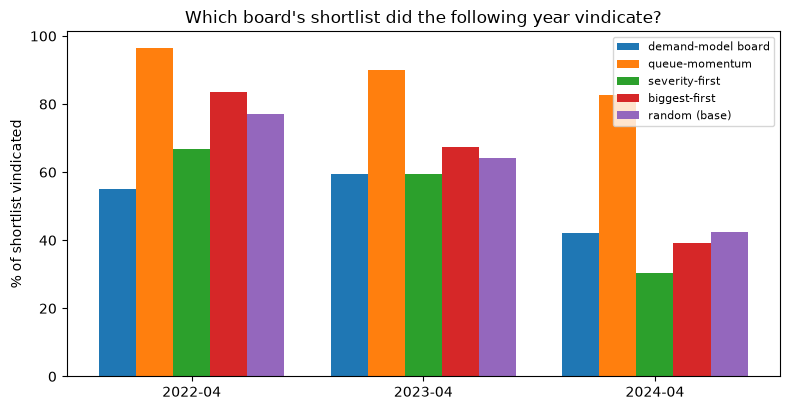

In [3]:
summary = (reg.groupby("origin")
              .agg(N_mean=("N", "mean"), base=("base_rate", "first"), n=("n_scorable", "first"),
                   model_mean=("model_board", "mean"), model_sd=("model_board", "std"),
                   severity=("severity_board", "mean"), size=("size_board", "mean"),
                   momentum=("momentum_board", "mean")))
print(summary.round(1).to_string())
print()
for origin_s, r in summary.iterrows():
    print(f"{origin_s}: demand board {r.model_mean:.1f}% (sd {r.model_sd:.1f}) | queue momentum "
          f"{r.momentum:.1f}% | severity {r.severity:.1f}% | size {r['size']:.1f}% | "
          f"base {r.base:.1f}% of {int(r.n):,}")
print()
# the queue-model board, only at the origin where 12's breach model exists
bc = pd.read_csv(CANON / "breach_calls.csv").set_index(["provider_code", "dept"])
origin = pd.Timestamp("2024-04-01")
out_cols = (gt18.columns >= origin) & (gt18.columns < origin + pd.DateOffset(months=H))
pre = gt18.loc[:, gt18.columns < origin].to_numpy()[:, -12:].mean(axis=1)
post = gt18.loc[:, out_cols].to_numpy().mean(axis=1)
og = post / np.where(pre > 0, pre, np.nan) - 1
ok = np.isfinite(og)
vind = og > BAND
qm = bc.queue_growth_pred_12m.reindex(gt18.index).to_numpy()
N24 = int(round(reg[reg.origin == "2024-04"].N.mean()))       # matched to the demand board's mean N
qm_rank = np.where(ok & np.isfinite(qm), qm, -np.inf)
qm_pick = np.zeros_like(ok); qm_pick[np.argsort(-qm_rank)[:N24]] = True
print(f"queue-model board, 2024-04 only (N={N24}, 12's trained breach forecast): "
      f"{vind[qm_pick & ok].mean() * 100:.1f}% vindicated vs base {vind[ok].mean() * 100:.1f}%")
print()
print("Vindication = the service's >18-week queue grew >5% over the 12 months after the origin.")
print("All boards pick the same N per (origin, seed); the random board's expectation is the base rate.")

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(summary))
for i, colname in enumerate(["model_mean", "momentum", "severity", "size", "base"]):
    ax.bar(x + i * 0.16, summary[colname], width=0.16,
           label=["demand-model board", "queue-momentum", "severity-first", "biggest-first", "random (base)"][i])
ax.set_xticks(x + 0.32); ax.set_xticklabels(summary.index)
ax.set_ylabel("% of shortlist vindicated"); ax.legend(fontsize=8)
ax.set_title("Which board's shortlist did the following year vindicate?")
plt.tight_layout()

## The queue-model board at every origin

Entry 54 left the trained queue model tested at one origin only. Here it is trained (seed 0, the
`12` configuration unchanged: FedAvg on `waiting_gt18`, 15 rounds x 2 local epochs) at the two
earlier origins as well, so the model-versus-momentum comparison exists everywhere the momentum
board does. Matched N per origin = the demand board's mean N, as before.

In [4]:
import torch
import torch.nn as nn

L, HIDDEN, ROUNDS, LOCAL_EPOCHS = 24, 128, 15, 2       # 12's configuration, unchanged
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
trusts = index.provider_code.to_numpy()
eye = np.eye(12, dtype=np.float32)

def new_model():
    return nn.Sequential(nn.Linear(L + 12, HIDDEN), nn.ReLU(), nn.Dropout(0.1),
                         nn.Linear(HIDDEN, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, H)).to(device)

def get_w(m): return [p.detach().clone() for p in m.parameters()]
def set_w(m, w):
    with torch.no_grad():
        for p, q in zip(m.parameters(), w): p.copy_(q)

def train_local(model, X, Y, epochs, lr=1e-3):
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.L1Loss()
    X, Y = X.to(device), Y.to(device)
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 256):
            b = perm[i:i + 256]
            opt.zero_grad(); loss_fn(model(X[b]), Y[b]).backward(); opt.step()

def queue_model_growth(origin):
    # train on gt18 strictly before `origin`, return each service's predicted 12-month queue growth
    torch.manual_seed(0)
    hist = gt18.loc[:, gt18.columns < origin].to_numpy(dtype=np.float32)
    norm = hist.mean(axis=1) + 1.0
    month_ix = np.array([m.month - 1 for m in gt18.columns[gt18.columns < origin]])
    clients = {}
    for code_ in np.unique(trusts):
        rows_ = np.flatnonzero(trusts == code_)
        xs, ys = [], []
        for r in rows_:
            s = hist[r] / norm[r]
            for t in range(len(s) - L - H + 1):
                xs.append(np.concatenate([s[t:t + L], eye[month_ix[t + L - 1]]]))
                ys.append(s[t + L:t + L + H])
        clients[code_] = (torch.tensor(np.array(xs)), torch.tensor(np.array(ys)))
    Xte = torch.tensor(np.concatenate(
        [hist[:, -L:] / norm[:, None], np.repeat(eye[month_ix[-1]][None, :], len(hist), axis=0)], axis=1))
    codes = list(clients)
    sizes = np.array([len(clients[c][0]) for c in codes], dtype=float)
    alpha = sizes / sizes.sum()
    w = get_w(new_model())
    model = new_model()
    for r in range(ROUNDS):
        acc = [torch.zeros_like(p) for p in w]
        for a, c in zip(alpha, codes):
            set_w(model, w)
            train_local(model, clients[c][0], clients[c][1], LOCAL_EPOCHS)
            for i, p in enumerate(get_w(model)):
                acc[i] += a * p
        w = acc
        set_w(model, w)
    model.eval()
    with torch.no_grad():
        pred = np.clip(model(Xte.to(device)).cpu().numpy() * norm[:, None], 0, None)
    ref12 = hist[:, -12:].mean(axis=1)
    return pred.mean(axis=1) / np.where(ref12 > 0, ref12, np.nan) - 1

qrows = []
for origin_s in sorted(reg.origin.unique()):
    origin = pd.Timestamp(origin_s + "-01")
    out_cols = (gt18.columns >= origin) & (gt18.columns < origin + pd.DateOffset(months=H))
    pre = gt18.loc[:, gt18.columns < origin].to_numpy()[:, -12:].mean(axis=1)
    post = gt18.loc[:, out_cols].to_numpy().mean(axis=1)
    og = post / np.where(pre > 0, pre, np.nan) - 1
    ok = np.isfinite(og)
    vind = og > BAND
    qg = queue_model_growth(origin)
    N = int(round(reg[reg.origin == origin_s].N.mean()))
    qrank = np.where(ok & np.isfinite(qg), qg, -np.inf)
    pick = np.zeros_like(ok); pick[np.argsort(-qrank)[:N]] = True
    mom = gt18[origin - pd.DateOffset(months=1)].to_numpy() / np.where(pre > 0, pre, np.nan) - 1
    mrank = np.where(ok & np.isfinite(mom), mom, -np.inf)
    mpick = np.zeros_like(ok); mpick[np.argsort(-mrank)[:N]] = True
    qrows.append({"origin": origin_s, "N": N,
                  "queue_model_board": vind[pick & ok].mean() * 100,
                  "queue_momentum_board": vind[mpick & ok].mean() * 100,
                  "base_rate": vind[ok].mean() * 100})
qtab = pd.DataFrame(qrows).set_index("origin")
print(qtab.round(1).to_string())
print()
print("model vs momentum at matched N, per origin - the model must beat the free signal to earn a place")
qtab.to_csv(CANON / "regret_queue_model.csv")
print("written: regret_queue_model.csv")

           N  queue_model_board  queue_momentum_board  base_rate
origin                                                          
2022-04  116               69.0                  96.6       77.1
2023-04  534               81.1                  90.4       64.3
2024-04  355               69.3                  82.5       42.3

model vs momentum at matched N, per origin - the model must beat the free signal to earn a place
written: regret_queue_model.csv


## How large should the shortlist be? The cost question, asked honestly

At matched N, every miss-to-waste cost ratio ranks boards identically: with G growers and N picks,
misses = G - TP and wasted picks = N - TP, so total cost is monotone in TP alone. The cost ratio
only becomes a real decision when it chooses **N itself** - a board that fears missing growers
(cost ratio 10:1) should shortlist far more services than one that fears wasted reviews (1:1).
Declared before the run: ratios 1:1, 3:1 and 10:1 (miss : waste), swept over N for the
queue-momentum board, cost normalised per scorable service.

In [5]:
rows_c = []
for origin_s in sorted(reg.origin.unique()):
    origin = pd.Timestamp(origin_s + "-01")
    out_cols = (gt18.columns >= origin) & (gt18.columns < origin + pd.DateOffset(months=H))
    pre = gt18.loc[:, gt18.columns < origin].to_numpy()[:, -12:].mean(axis=1)
    post = gt18.loc[:, out_cols].to_numpy().mean(axis=1)
    og = post / np.where(pre > 0, pre, np.nan) - 1
    ok = np.isfinite(og)
    vind = og > BAND
    G = int((vind & ok).sum())
    mom = gt18[origin - pd.DateOffset(months=1)].to_numpy() / np.where(pre > 0, pre, np.nan) - 1
    order = np.argsort(-np.where(ok & np.isfinite(mom), mom, -np.inf))
    hits = np.cumsum(vind[order])                       # TP as the shortlist grows down the ranking
    Ns = np.arange(1, int(ok.sum()) + 1)
    for ratio in [1, 3, 10]:
        cost = (ratio * (G - hits[:len(Ns)]) + (Ns - hits[:len(Ns)])) / ok.sum()
        best_n = int(Ns[np.argmin(cost)])
        rows_c.append({"origin": origin_s, "cost_ratio_miss_to_waste": ratio, "growers": G,
                       "optimal_N": best_n, "coverage_pct": best_n / ok.sum() * 100,
                       "TP_at_optimum": int(hits[best_n - 1]),
                       "cost_per_service": cost[best_n - 1]})
ctab = pd.DataFrame(rows_c)
print(ctab.round(2).to_string(index=False))
print()
print("Read: the dearer a missed grower, the wider the shortlist. At 1:1 the board reviews only the")
print("strongest momentum; at 10:1 it reviews most of the panel. The shortlist size is a policy")
print("choice priced here, not a modelling constant - which is exactly what a board should decide.")
ctab.to_csv(CANON / "regret_costs.csv", index=False)
print("written: regret_costs.csv")

 origin  cost_ratio_miss_to_waste  growers  optimal_N  coverage_pct  TP_at_optimum  cost_per_service
2022-04                         1     1492       1549         80.05           1344              0.18
2022-04                         3     1492       1934         99.95           1492              0.23
2022-04                        10     1492       1934         99.95           1492              0.23
2023-04                         1     1255       1214         62.19           1011              0.23
2023-04                         3     1255       1616         82.79           1173              0.35
2023-04                        10     1255       1952        100.00           1255              0.36
2024-04                         1      824        776         39.82            565              0.24
2024-04                         3      824       1062         54.49            670              0.44
2024-04                        10      824       1949        100.00            824         

## What this settles

**A caveat the momentum lift must carry.** The queue is an integrator: a service whose gt18 count
has just risen keeps part of that rise in next year's mean arithmetically, so selection by momentum
and vindication by mean-over-mean growth share a mechanical component. The base-rate comparison
survives (every board faces the same outcome definition), but the momentum board's margin should be
read as "queues persist" at least as much as "the future was foreseen". The trained breach model's
69.3% at 2024-04 carries the same caveat through its own reliance on recent levels.


Whether the forecaster-led shortlist is the right thing to put in front of a board, measured the way
a board would measure it. It does not claim any capacity outcome - no allocation was executed - and
the demand-trained model is being scored here on a breach-growth vindication, which is exactly the
cross-variable gap `12` addresses; the queue-model and cost sections above are that re-scoring, and the
cost-optimal shortlist size is now a priced policy choice rather than an assumption.